In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
file="../data/processed/cleaned_telco.csv"
df=pd.read_csv(file)


In [12]:
df.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

In [ ]:
#Overall Churn Percentage
churn_count=df["churn"].value_counts()
print("Churn counts-")
print(churn_count)
print("-"*20)
for category,count in churn_count.items():
    p=count/len(df)*100
    print(f"{category}:{p:.1f}%")


Churn counts-
churn
No     5174
Yes    1869
Name: count, dtype: int64
--------------------
No:73.5%
Yes:26.5%


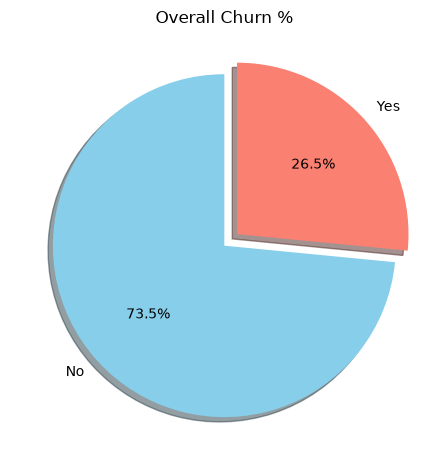

In [98]:
plt.pie(churn_count,labels=churn_count.index,autopct="%1.1f%%",
    startangle=90,
    colors=["skyblue", "salmon"],
    explode=(0, 0.1),
    shadow=True)
plt.title("Overall Churn %")
plt.tight_layout()
plt.show()

In [46]:
# contract type Churn analysis 
contract_churn=pd.crosstab(df["contract"],df["churn"],normalize="index")*100
print(contract_churn.round(1))

churn             No   Yes
contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


<Figure size 400x400 with 0 Axes>

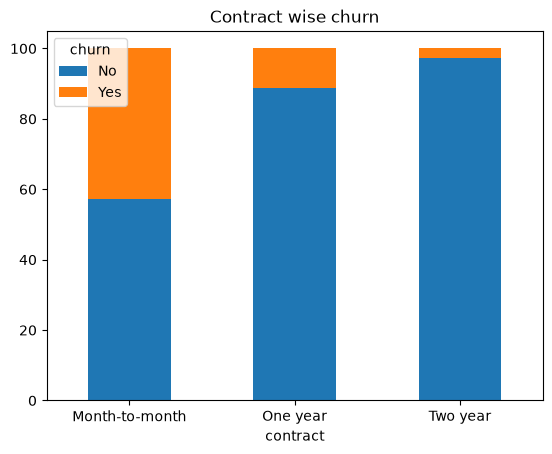

In [56]:
#contract churn bar chart
plt.figure(figsize=(4,4))
contract_churn.plot(kind="bar",stacked=True)
plt.title("Contract wise churn")
plt.xticks(rotation=0)
plt.show()

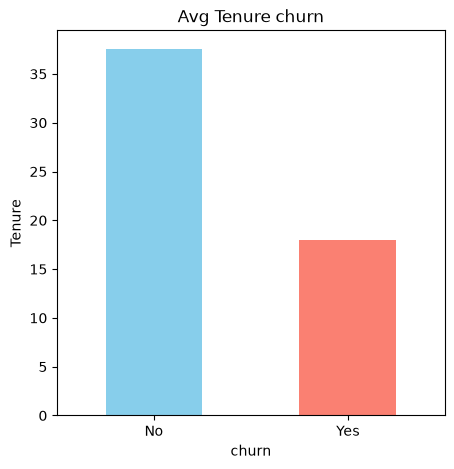

In [61]:
#tenure churn
avg_tenure_churn=df.groupby("churn")["tenure"].mean()
avg_tenure_churn.plot(kind="bar",figsize=(5,5),color=["skyblue","salmon"])
plt.title("Avg Tenure churn")
plt.xticks(rotation=0)
plt.ylabel("Tenure")
plt.show()

C:\Users\valla\AppData\Local\Temp\ipykernel_18548\4236157268.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


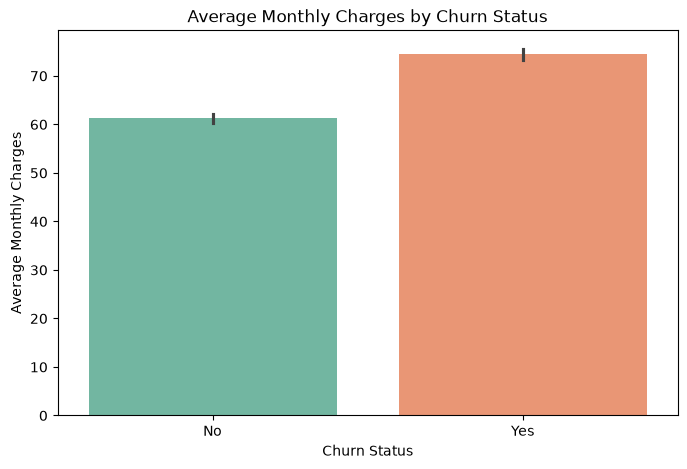

In [75]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="churn",
    y="monthlycharges",
    palette="Set2"
)

plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Monthly Charges")
plt.show()

Text(0.5, 1.0, 'Distribution of Monthly Charges by Churn Status')

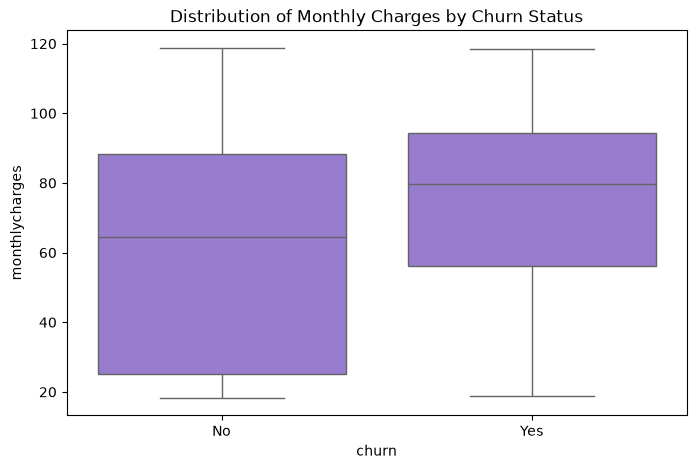

In [77]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="churn",
    y="monthlycharges",
    color="mediumpurple"
)
plt.title("Distribution of Monthly Charges by Churn Status")

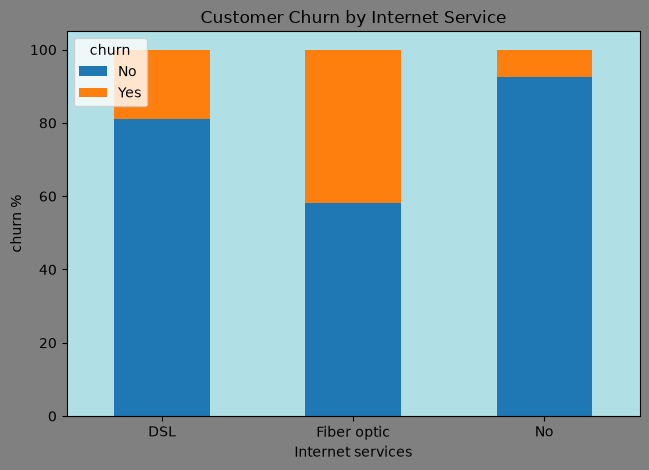

In [ ]:
rate=pd.crosstab(df["internetservice"],df["churn"],normalize="index")*100
rate.plot(kind="bar",stacked=True)
plt.title("Customer Churn by Internet Service")
plt.xticks(rotation=0)
plt.tight_layout()
plt.xlabel("Internet services")
plt.ylabel("churn %")
plt.gcf().set_facecolor("grey")
plt.gca().set_facecolor("powderblue")
plt.show()

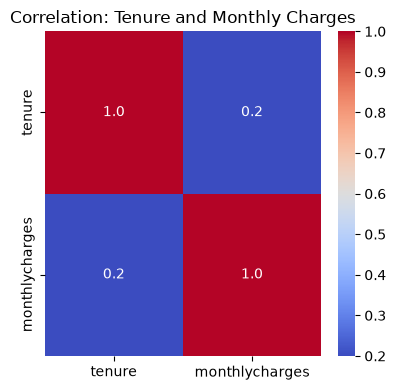

In [95]:
#tenure churn
avg_tenure_churn=df.groupby("churn")["tenure"].mean()
tenure_=df[["tenure","monthlycharges"]].corr().round(1)
plt.figure(figsize=(4,4))
sns.heatmap(tenure_,annot=True,cmap="coolwarm",fmt=".1f")
plt.title("Correlation: Tenure and Monthly Charges")
plt.tight_layout()
plt.show()